# Moving-object tracking (8-second prediction)

1. **1D along-track uncertainty plot**.
2. **Full 2D trajectory plot**, with 5σ observation ellipses and 1σ forecast regions (including the classical forecast).

In [2]:
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from object_tracking import (
    run_tracking, tracking_forecast_summary,
    plot_along_track, plot_2d_full,
)

# 100,000 screen samples, D=128, lag=40 ms.
# QUICK_CHECK uses 5,000 screens to test formatting, but FI and forecast
# uncertainties will differ from the publication-quality calculation.
QUICK_CHECK = False
SCREENS = 5_000 if QUICK_CHECK else 100_000
HORIZON_S = 8.0
SAVE = True


## Compute the optical FI and generate tracking data

The computation uses **D=128**, pixel pitch **0.0640625 m**, $r_0=0.177$ m, $L_0=22$ m, 10 m/s wind, **40 ms** photon separation, 550-nm wavelength, 256 focal bins, and 100,000 independent 1D-slice Gaussian screens. The observation uses **400 photons in 0.25 s**, with RFS branch fractions 0.65 (relative displacement), 0.30 (absolute anchors), and 0.05 (unused). The classical receiver retains both centroid and relative-displacement FI.

In [5]:
fi_record, data_8s = run_tracking(
    screens=SCREENS, horizon_s=HORIZON_S, verbose=True
)

print('Product-FT pair-FI matrix [centroid, displacement]:')
print(np.array(fi_record['full_pair_FI_cross_validated']))
print('Likelihood checks:', fi_record['likelihood_checks'])
summary = tracking_forecast_summary(data_8s)
for name, value in summary.items():
    print(f'{name}: {value:.6g}')


Accumulated [50000, 50000] phase-screen realizations in 12.8 seconds
Product-FT pair-FI matrix [centroid, displacement]:
[[1.26576194e+00 1.35629213e-03]
 [1.35629213e-03 7.67921033e+00]]
Likelihood checks: {'likelihood_sum': 1.0, 'likelihood_min': 5.171108897165404e-07, 'derivative_c_sum': -2.7755575615628914e-17, 'derivative_delta_sum': 6.938893903907228e-18, 'max_half_likelihood_difference': 5.32720988668446e-06, 'ft_centroid_FI_plugin_upward_bias': 0.10205602152901694, 'ft_displacement_FI_plugin_upward_bias': 0.025787402795609538}
prediction_horizon_s: 8
velocity_FI_ratio: 137.337
prediction_photon_cost_ratio: 125.7
sigma_RFS_mas: 156.952
sigma_productFT_mas: 1759.69


## Figure 1 — 1D along-track plot

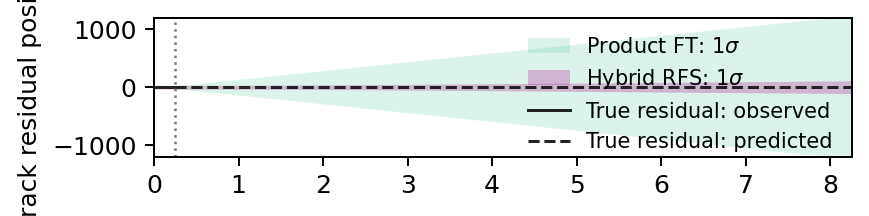

In [7]:
fig_1d = plot_along_track(
    data_8s,
    figsize=(5, 1),
    ylim=(-1200, 1200),
    linewidth=1.2,
    dpi=180,
    show_fits=False,
    show_bands=True,
    title=None,
    xlabel=None,
    save_path=None,
)
if SAVE:
    fig_1d.savefig('tracking_D128_40ms_8s_1d.pdf', bbox_inches='tight')
    fig_1d.savefig('tracking_D128_40ms_8s_1d.png', dpi=300, bbox_inches='tight')
plt.show()


## Figure 2 — 2D trajectory plot

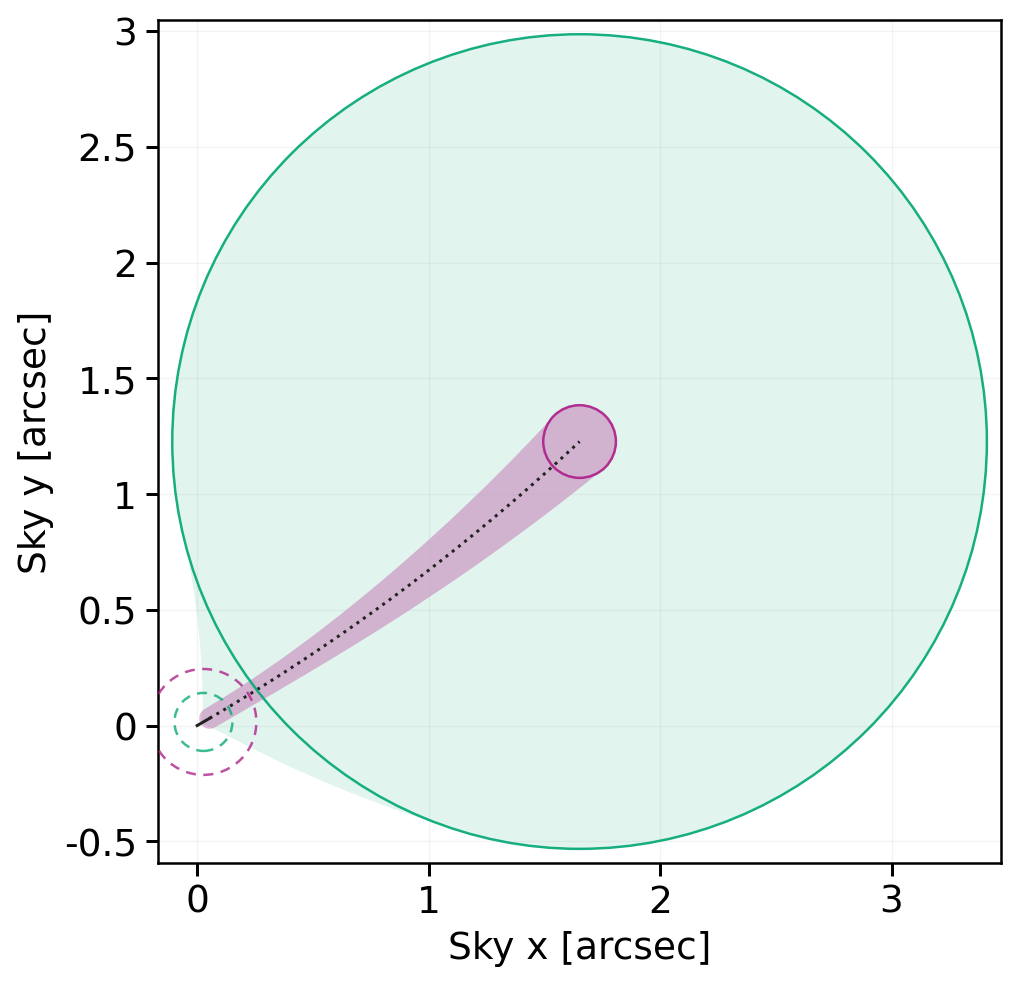

In [9]:
figsize = (7, 6)
dpi = 180
xlim = None
ylim = None
xlabel, ylabel = 'Sky x [arcsec]', 'Sky y [arcsec]'
observation_sigma = 5.0
forecast_sigma = 1.0
show_classical_tube = True
show_final_ellipses = True
show_fits = False
tube_grid_pixels = 340
y_exaggeration = 1.0
linewidth = 1.2
markersize = 0
rc = {
    'font.family': 'DejaVu Sans',
    'font.size': 15,
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.2,
    'ytick.major.width': 1.2,
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'savefig.transparent': False,
}

p_plot = replace(
    data_8s['params'],
    observation_sigma_2d=observation_sigma,
    forecast_sigma_2d=forecast_sigma,
    show_classical_forecast_tube=show_classical_tube,
    tube_grid_pixels=tube_grid_pixels,
    y_exaggeration_2d=y_exaggeration,
)
data_plot = {**data_8s, 'params': p_plot}

fig_full = plot_2d_full(
    data_plot,
    figsize=figsize, dpi=dpi, rc=rc,
    xlim=xlim, ylim=ylim,
    show_final_ellipses=show_final_ellipses,
    show_fits=show_fits,
    markersize=markersize,
    linewidth=linewidth,
    title=None,
    save_path=None,
)
ax = fig_full.axes[0]
ax.set_xlabel(xlabel, fontsize=15)
ax.set_ylabel(ylabel, fontsize=15)
ax.tick_params(axis='both', direction='out', labelsize=15, length=5, width=1.2)
ax.set_aspect('equal', adjustable='box')
ax.grid(True, alpha=0.15, linewidth=0.5)
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)

# The first two patches are observation ellipses; the next two are
# the terminal forecast ellipses, in the original plot's construction.
if len(ax.patches) >= 4:
    for patch in ax.patches[2:4]:
        patch.set_linestyle('-')
        patch.set_linewidth(1)

arcsec_formatter = FuncFormatter(lambda x, pos: f'{x / 1000:g}')
ax.xaxis.set_major_formatter(arcsec_formatter)
ax.yaxis.set_major_formatter(arcsec_formatter)

if SAVE:
    fig_full.savefig('tracking_D128_40ms_8s_full.pdf', bbox_inches='tight')
    fig_full.savefig('tracking_D128_40ms_8s_full.png', dpi=300, bbox_inches='tight')
plt.show()
